
# Machine Learning Assignment 2

## Classification Models and Performance Evaluation

**Programme:** M.Tech Artificial Intelligence and Machine Learning

**Subject:** Machine Learning

### Objective

The objective of this assignment is to implement five different machine learning classification algorithms using a common dataset, evaluate their performance using six evaluation metrics, and deploy an interactive Streamlit application.

### Classification Models

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

### Evaluation Metrics

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)


In [13]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 130.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 150.8 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 108.8 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


In [7]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import joblib

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")
print("Scikit-learn version:", sklearn.__version__)

Libraries imported successfully.
Scikit-learn version: 1.9.1


## 1. Dataset Loading

The dataset used for this assignment is a publicly available
classification dataset.

The dataset is stored in a CSV file named `dataset.csv`.

In [9]:
df = pd.read_csv("dataset.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Dataset Exploration

The dataset is examined to understand its structure, feature types,
target distribution, and data quality before model training.

In [11]:
print("First five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.372583
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,0.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [13]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Number of rows: 569
Number of columns: 31

Missing values in each column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Duplicate row

In [15]:
print("Target distribution:")
print(df["target"].value_counts())

print("\nTarget distribution in percentage:")
print(df["target"].value_counts(normalize=True) * 100)

Target distribution:
target
0    357
1    212
Name: count, dtype: int64

Target distribution in percentage:
target
0    62.741652
1    37.258348
Name: proportion, dtype: float64


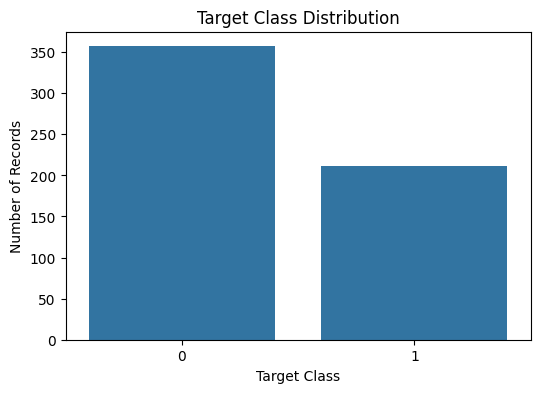

In [17]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="target")

plt.title("Target Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")

plt.show()

### Dataset Observations

The dataset contains 569 records and 31 columns, including the target
column. Therefore, it contains 30 input features.

The target variable is named `target` and contains two classes:
0 and 1.

The dataset contains no missing values. The target distribution shows
357 records in class 0 and 212 records in class 1.

The dataset satisfies the assignment requirements of having at least
12 input features and 500 instances.

## 3. Data Preparation

The target column is separated from the input features.

The remaining 30 columns are used as independent variables, while
the `target` column is used as the dependent variable.

In [19]:
X = df.drop("target", axis=1)
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (569, 30)
Target shape: (569,)


### Train-Test Split

The dataset is divided into training and testing subsets.

80% of the data is used for training, and 20% is used for testing.
The random state is fixed at 42 to make the results reproducible.

Stratification is applied to maintain the target class proportions
in both subsets.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Target: (455,)
Testing Target: (114,)


## 4. Model Implementation

Five classification algorithms are implemented using the same
training and testing data.

Standardization is applied to Logistic Regression, KNN, and SVM
because these algorithms are sensitive to feature scales.

Decision Tree and Gaussian Naive Bayes are trained without
standardization.

In [23]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": GaussianNB(),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ])
}

print("Five classification models created successfully.")

for model_name in models:
    print(model_name)

Five classification models created successfully.
Logistic Regression
Decision Tree
KNN
Naive Bayes
SVM


### Model Training

Each classification model is trained using the same training dataset.

This ensures a consistent basis for comparing the performance
of all five algorithms.

In [25]:
for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(model_name, "trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
KNN trained successfully.
Naive Bayes trained successfully.
SVM trained successfully.


## 5. Model Evaluation

The trained models are evaluated on the testing dataset.

The following performance metrics are used:

- Accuracy
- Area Under the ROC Curve (AUC)
- Precision
- Recall
- F1-score
- Matthews Correlation Coefficient (MCC)

These metrics provide different perspectives on classification
performance.

In [27]:
results = []

for model_name, model in models.items():

    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_probability = model.predict_proba(X_test)[:, 1]
    else:
        y_probability = model.decision_function(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_probability),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1 Score": f1_score(y_test, y_pred, average="weighted"),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9652,0.9649,0.9647,0.9245
1,Decision Tree,0.9298,0.9246,0.9298,0.9298,0.9298,0.8492
2,KNN,0.9561,0.9823,0.9569,0.9561,0.9558,0.9058
3,Naive Bayes,0.9386,0.9934,0.9440,0.9386,0.9372,0.8715
4,SVM,0.9737,0.9947,0.9747,0.9737,0.9735,0.9442


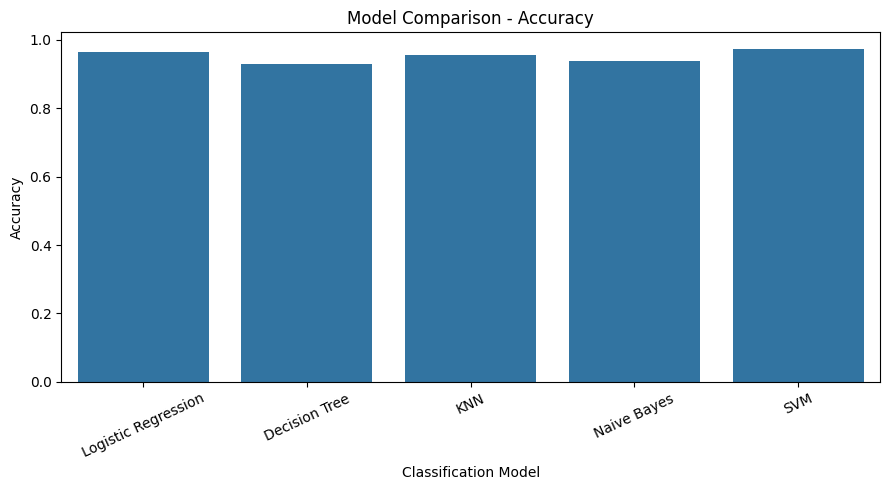

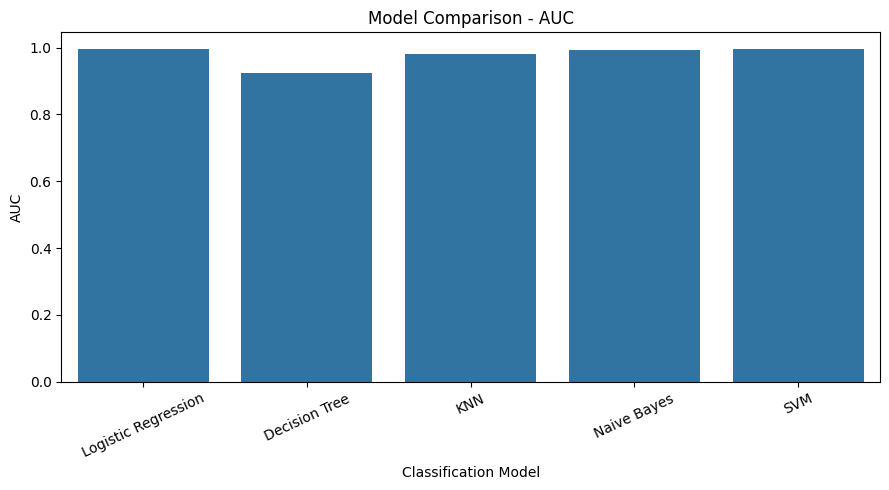

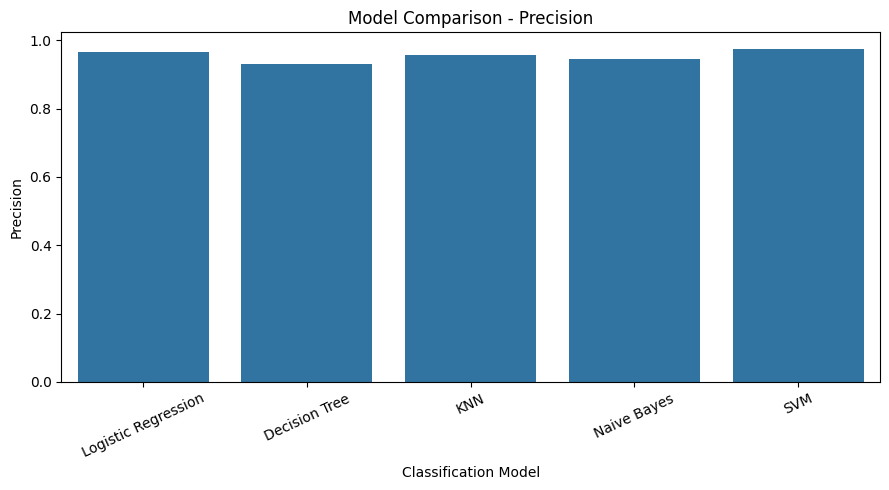

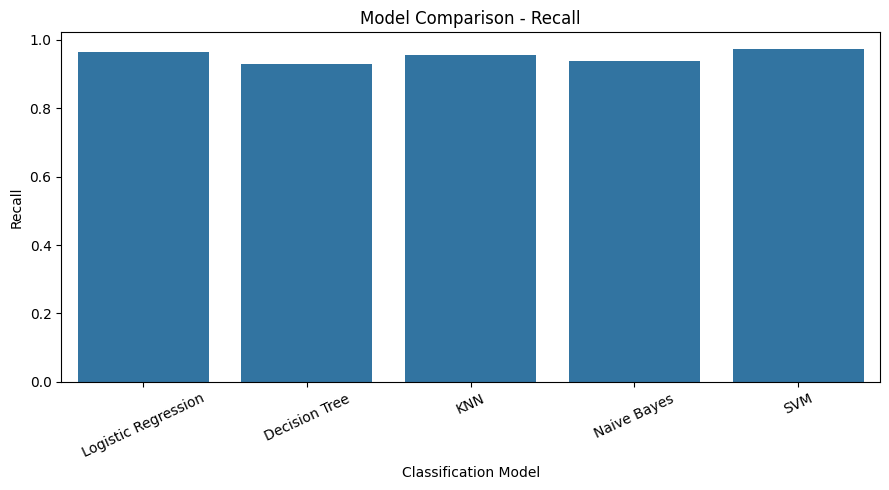

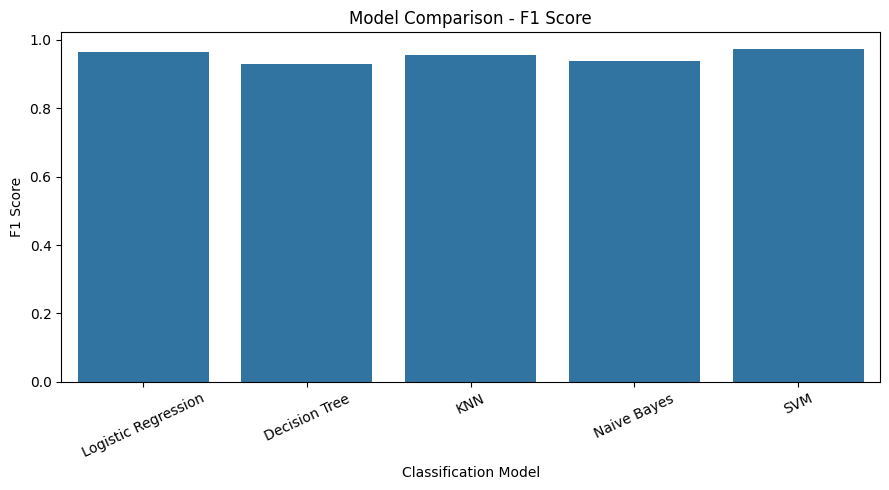

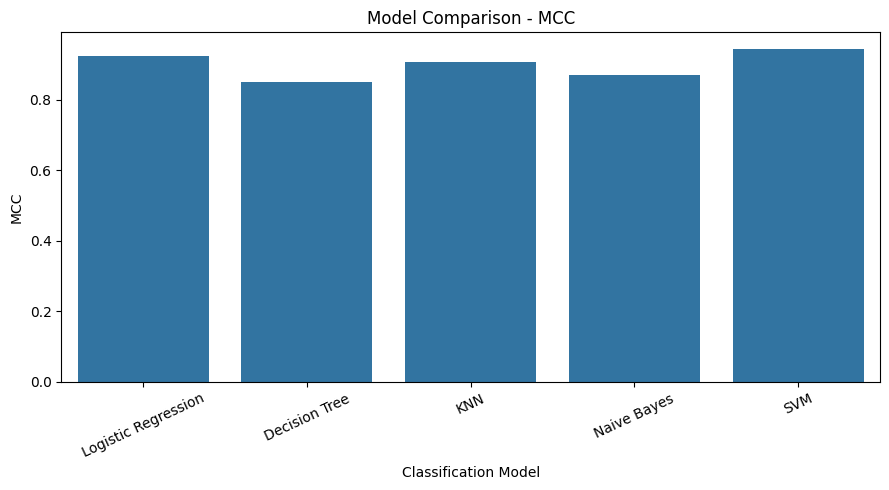

In [29]:
metrics_to_plot = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Classification Model")
    plt.ylabel(metric)
    plt.xticks(rotation=25)

    plt.tight_layout()
    plt.show()

### Confusion Matrix Analysis

A confusion matrix is generated for each trained model to examine
the number of correct and incorrect predictions for each class.

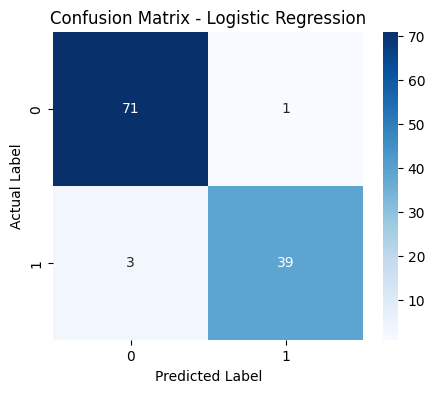


Classification Report - Logistic Regression
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        72
           1       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



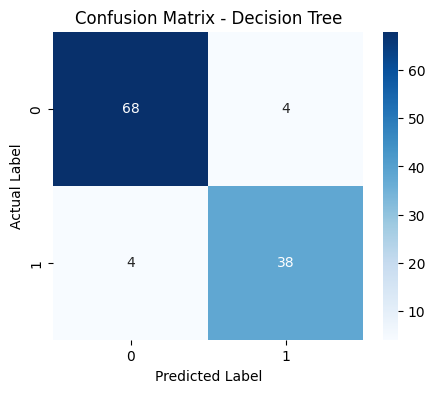


Classification Report - Decision Tree
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        72
           1       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



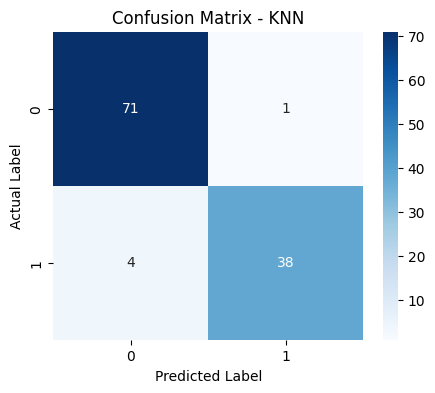


Classification Report - KNN
              precision    recall  f1-score   support

           0       0.95      0.99      0.97        72
           1       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



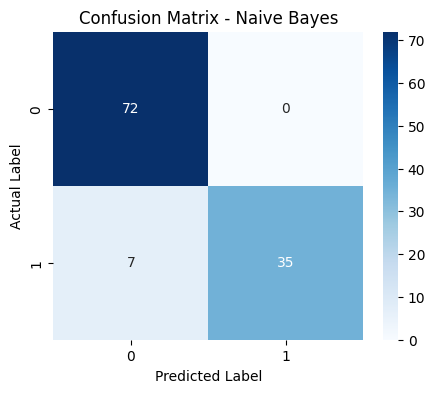


Classification Report - Naive Bayes
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        72
           1       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



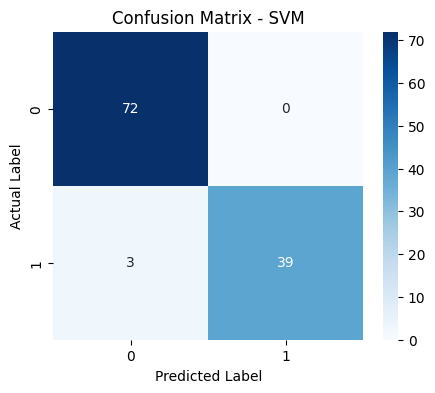


Classification Report - SVM
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [31]:
for model_name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["0", "1"],
        yticklabels=["0", "1"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.show()

    print(f"\nClassification Report - {model_name}")
    print(classification_report(y_test, y_pred))

In [33]:
best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("Best-performing model based on F1 Score:")
print(best_model)

Best-performing model based on F1 Score:
Model             SVM
Accuracy     0.973684
AUC          0.994709
Precision    0.974737
Recall       0.973684
F1 Score     0.973465
MCC          0.944155
Name: 4, dtype: object


### Overall Model Comparison

The five classification algorithms were evaluated using the same
testing dataset and six performance metrics.

The model with the highest F1-score is identified as the best
performing model based on the selected comparison criterion.

The final observations should consider Accuracy, AUC, Precision,
Recall, F1-score, and MCC rather than relying on only one metric.

## 6. Saving Trained Models

The trained classification models are saved so that they can be
loaded later by the Streamlit application without retraining.

In [35]:
os.makedirs("model", exist_ok=True)

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}

for model_name, filename in model_files.items():

    joblib.dump(
        models[model_name],
        os.path.join("model", filename)
    )

    print(model_name, "saved successfully.")

Logistic Regression saved successfully.
Decision Tree saved successfully.
KNN saved successfully.
Naive Bayes saved successfully.
SVM saved successfully.


In [37]:
test_data = X_test.copy()

test_data["target"] = y_test

test_data.to_csv("test_data.csv", index=False)

print("Test data saved successfully.")
print("Test data shape:", test_data.shape)

Test data saved successfully.
Test data shape: (114, 31)


In [39]:
results_df.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [41]:
feature_columns = list(X.columns)

with open("feature_columns.json", "w") as file:
    json.dump(feature_columns, file, indent=4)

print("Feature columns saved successfully.")
print("Number of features:", len(feature_columns))

Feature columns saved successfully.
Number of features: 30


In [43]:
print("Files in current directory:")

for item in os.listdir("."):
    print(item)

print("\nFiles inside model folder:")

for item in os.listdir("model"):
    print(item)

Files in current directory:
dataset.csv
.ipynb_checkpoints
AIML_Assignement2.ipynb
model
test_data.csv
model_comparison.csv
feature_columns.json

Files inside model folder:
logistic_regression.joblib
decision_tree.joblib
knn.joblib
naive_bayes.joblib
svm.joblib
